In [16]:
from bikes_data import make_rentals

# Generate the reproducible dataset
df = make_rentals()

# Display the first five rows
print(df.head())

# Display descriptive statistics
print(df["rentals"].describe().round(2))

   hour  temperature_c  rain_mm  wind_kph  is_weekend station_type  rentals
0    20           28.9      0.0      10.9           1  residential        4
1     4           22.8      0.0       5.9           0         park        1
2     0           13.6      3.0      15.9           0         park        0
3    15            9.6      0.0      26.0           1  residential       13
4     8            7.4      3.0       9.8           0         park        0
count    6000.00
mean       10.59
std        14.17
min         0.00
25%         2.00
50%         5.00
75%        13.00
max       105.00
Name: rentals, dtype: float64


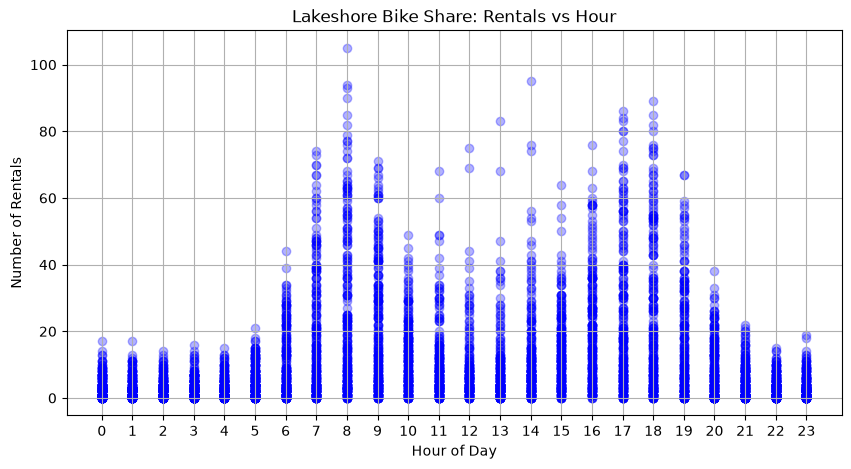

In [17]:
import matplotlib.pyplot as plt

# Plot rentals against the hour
plt.figure(figsize=(10, 5))

plt.scatter(df["hour"], df["rentals"], alpha=0.3, color="blue")

plt.xlabel("Hour of Day")
plt.ylabel("Number of Rentals")
plt.title("Lakeshore Bike Share: Rentals vs Hour")

plt.xticks(range(24))
plt.grid(True)

plt.show()

In [18]:
from sklearn.model_selection import train_test_split

# Fixed random seed
RANDOM_STATE = 42

# First split: 60% training, 40% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.40,
    random_state=RANDOM_STATE
)

# Second split: divide temporary data equally
# 20% validation and 20% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=RANDOM_STATE
)

# Verify split sizes
print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))

Training rows: 3600
Validation rows: 1200
Test rows: 1200


In [19]:
import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader

In [20]:
class BikeRentalDataset(Dataset):
    def __init__(self, X, y):
        # Convert features to float32 tensors
        self.X = torch.tensor(
            np.asarray(X, dtype=np.float32),
            dtype=torch.float32
        )

        # Convert targets to float32 tensors
        self.y = torch.tensor(
            np.asarray(y, dtype=np.float32).reshape(-1, 1),
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [23]:
from bikes_data import make_rentals
from sklearn.model_selection import train_test_split

# Fixed seed for reproducibility
RANDOM_STATE = 42

# Load the dataset
df = make_rentals()

# Split 60% training, 40% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.40,
    random_state=RANDOM_STATE
)

# Split remaining 40% into validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=RANDOM_STATE
)

# Separate features and target
X_train = train_df.drop(columns=["rentals"])
y_train = train_df["rentals"]

X_val = val_df.drop(columns=["rentals"])
y_val = val_df["rentals"]

X_test = test_df.drop(columns=["rentals"])
y_test = test_df["rentals"]

# Verify sizes
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (3600, 6)
Validation: (1200, 6)
Test: (1200, 6)


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Define features
numeric_features = [
    "hour",
    "temperature_c",
    "rain_mm",
    "wind_kph",
    "is_weekend"
]

categorical_features = ["station_type"]

# Create preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    sparse_threshold=0
)

# Fit preprocessing on TRAINING data only
X_train_prepared = preprocessor.fit_transform(X_train)

# Transform validation and test data
X_val_prepared = preprocessor.transform(X_val)
X_test_prepared = preprocessor.transform(X_test)

print("Training:", X_train_prepared.shape)
print("Validation:", X_val_prepared.shape)
print("Test:", X_test_prepared.shape)

Training: (3600, 8)
Validation: (1200, 8)
Test: (1200, 8)


In [25]:
train_dataset = BikeRentalDataset(X_train_prepared, y_train)
val_dataset = BikeRentalDataset(X_val_prepared, y_val)
test_dataset = BikeRentalDataset(X_test_prepared, y_test)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Training: 3600
Validation: 1200
Test: 1200


In [27]:
from torch.utils.data import DataLoader

# Set batch size
BATCH_SIZE = 32

# Training DataLoader - shuffle enabled
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

# Validation DataLoader - no shuffling
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Test DataLoader - no shuffling
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("All three DataLoaders created successfully!")

All three DataLoaders created successfully!


In [29]:
import torch
from torch.utils.data import RandomSampler, SequentialSampler

# Verify individual observations
for dataset in [train_dataset, val_dataset, test_dataset]:
    X, y = dataset[0]
    assert X.dtype == torch.float32
    assert y.dtype == torch.float32

# Verify DataLoader shuffling
assert isinstance(train_loader.sampler, RandomSampler)
assert isinstance(val_loader.sampler, SequentialSampler)
assert isinstance(test_loader.sampler, SequentialSampler)

# Verify training batch
X_batch, y_batch = next(iter(train_loader))

assert X_batch.shape == (32, 8)
assert y_batch.shape == (32, 1)

print("All Dataset and DataLoader tests passed!")

print("All Dataset and DataLoader tests passed!")

All Dataset and DataLoader tests passed!
All Dataset and DataLoader tests passed!


In [30]:
import torch
import torch.nn as nn

In [32]:
class BikeRentalNN(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)

In [33]:
# Set seed for reproducibility
torch.manual_seed(42)

# Determine number of input features automatically
input_size = X_train_prepared.shape[1]

# Create neural network
model = BikeRentalNN(input_size)

print(model)

BikeRentalNN(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [34]:
X_batch, y_batch = next(iter(train_loader))

predictions = model(X_batch)

print("Input shape:", X_batch.shape)
print("Prediction shape:", predictions.shape)

assert predictions.shape == (32, 1)
assert isinstance(model.network[-1], nn.Linear)

print("Neural network architecture tests passed!")

Input shape: torch.Size([32, 8])
Prediction shape: torch.Size([32, 1])
Neural network architecture tests passed!


In [35]:
import torch
import torch.nn as nn

In [36]:
def run_epoch(model, loader, loss_fn, optimizer=None):
    # Training when optimizer is provided
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    total_absolute_error = 0.0
    total_samples = 0

    # Enable gradients only during training
    with torch.set_grad_enabled(training):
        for X_batch, y_batch in loader:

            # Forward pass
            predictions = model(X_batch)

            # Calculate loss
            loss = loss_fn(predictions, y_batch)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            # Accumulate errors across all observations
            batch_size = y_batch.size(0)

            total_loss += loss.item() * batch_size

            total_absolute_error += (
                torch.abs(predictions - y_batch).sum().item()
            )

            total_samples += batch_size

    mean_loss = total_loss / total_samples
    mean_mae = total_absolute_error / total_samples

    return mean_loss, mean_mae

In [37]:
# Loss function
loss_fn = nn.MSELoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [38]:
train_loss, train_mae = run_epoch(
    model,
    train_loader,
    loss_fn,
    optimizer
)

print("Training Loss:", round(train_loss, 4))
print("Training MAE:", round(train_mae, 4))

Training Loss: 268.1504
Training MAE: 9.5125


In [39]:
val_loss, val_mae = run_epoch(
    model,
    val_loader,
    loss_fn
)

print("Validation Loss:", round(val_loss, 4))
print("Validation MAE:", round(val_mae, 4))

Validation Loss: 231.2769
Validation MAE: 9.1693


In [40]:
# Save model weights before validation
weights_before = [
    p.detach().clone() for p in model.parameters()
]

# Run evaluation
loss, mae = run_epoch(model, val_loader, loss_fn)

# Verify weights did not change
for before, after in zip(weights_before, model.parameters()):
    assert torch.equal(before, after)

print("Evaluation does not update model weights.")
print("Mean Loss:", round(loss, 4))
print("Mean Absolute Error:", round(mae, 4))

Evaluation does not update model weights.
Mean Loss: 231.2769
Mean Absolute Error: 9.1693


In [41]:
import copy
import pandas as pd

def train_model(model, train_loader, val_loader, loss_fn, optimizer, epochs=100):

    history = []
    best_val_loss = float("inf")
    best_epoch = 0
    best_weights = copy.deepcopy(model.state_dict())

    for epoch in range(1, epochs + 1):

        # Train for one epoch
        train_loss, train_mae = run_epoch(
            model, train_loader, loss_fn, optimizer
        )

        # Evaluate on validation data
        val_loss, val_mae = run_epoch(
            model, val_loader, loss_fn
        )

        # Record metrics for every epoch
        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_mae": val_mae
        })

        # Save weights when validation loss improves
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_weights = copy.deepcopy(model.state_dict())

        # Display progress
        print(
            f"Epoch {epoch:03d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val MAE: {val_mae:.4f}"
        )

    # Restore weights from the best epoch
    model.load_state_dict(best_weights)

    print(f"\nBest epoch: {best_epoch}")
    print(f"Lowest validation loss: {best_val_loss:.4f}")
    print("Best model weights restored successfully!")

    return pd.DataFrame(history)

In [42]:
# Reinitialize model for a fresh training run
torch.manual_seed(42)

model = BikeRentalNN(X_train_prepared.shape[1])

loss_fn = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Train for 100 epochs
history = train_model(
    model,
    train_loader,
    val_loader,
    loss_fn,
    optimizer,
    epochs=100
)

Epoch 001/100 | Train Loss: 267.2774 | Val Loss: 229.4696 | Val MAE: 9.2289
Epoch 002/100 | Train Loss: 174.3179 | Val Loss: 189.1155 | Val MAE: 9.4422
Epoch 003/100 | Train Loss: 156.4382 | Val Loss: 175.1133 | Val MAE: 9.0501
Epoch 004/100 | Train Loss: 146.0816 | Val Loss: 163.5826 | Val MAE: 8.5963
Epoch 005/100 | Train Loss: 136.7707 | Val Loss: 152.5628 | Val MAE: 8.0461
Epoch 006/100 | Train Loss: 126.8061 | Val Loss: 141.2778 | Val MAE: 7.5531
Epoch 007/100 | Train Loss: 117.7435 | Val Loss: 131.3453 | Val MAE: 7.6388
Epoch 008/100 | Train Loss: 111.6035 | Val Loss: 125.2623 | Val MAE: 7.4605
Epoch 009/100 | Train Loss: 107.9329 | Val Loss: 121.6431 | Val MAE: 7.3062
Epoch 010/100 | Train Loss: 105.5532 | Val Loss: 118.8624 | Val MAE: 7.2918
Epoch 011/100 | Train Loss: 103.2910 | Val Loss: 118.9306 | Val MAE: 7.5047
Epoch 012/100 | Train Loss: 102.3267 | Val Loss: 116.8229 | Val MAE: 7.0657
Epoch 013/100 | Train Loss: 100.8788 | Val Loss: 114.2583 | Val MAE: 7.0316
Epoch 014/10

In [43]:
# Display the first five epochs
print(history.head())

# Find the best epoch
best_row = history.loc[history["val_loss"].idxmin()]

print("\nBest epoch:", int(best_row["epoch"]))
print("Best validation loss:", round(best_row["val_loss"], 4))
print("Best validation MAE:", round(best_row["val_mae"], 4))

   epoch  train_loss    val_loss   val_mae
0      1  267.277412  229.469613  9.228851
1      2  174.317856  189.115494  9.442229
2      3  156.438195  175.113329  9.050078
3      4  146.081637  163.582563  8.596299
4      5  136.770700  152.562829  8.046075

Best epoch: 100
Best validation loss: 23.7446
Best validation MAE: 3.4244


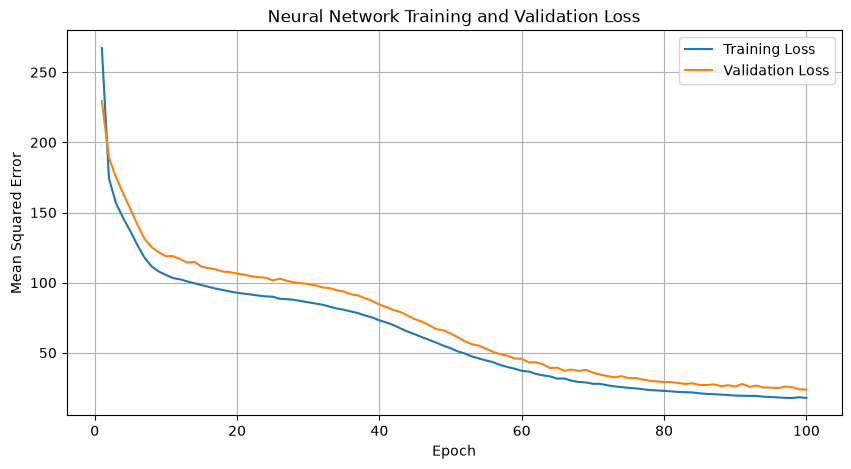

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history["epoch"],
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    history["epoch"],
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Neural Network Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

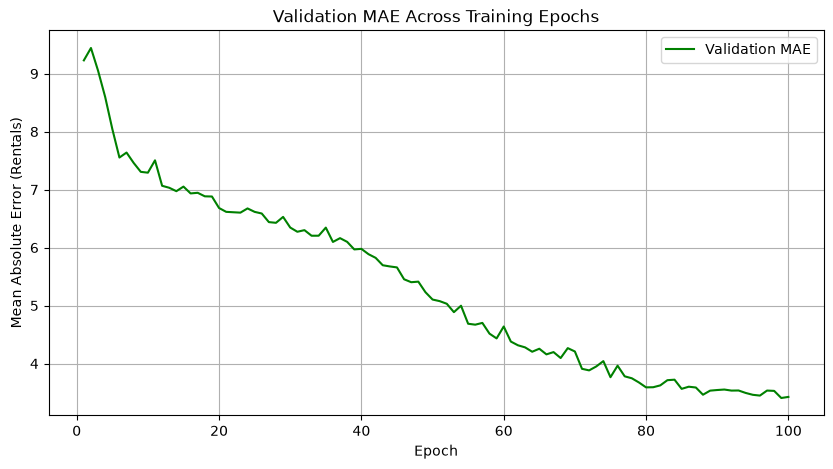

In [45]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["epoch"],
    history["val_mae"],
    label="Validation MAE",
    color="green"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Error (Rentals)")
plt.title("Validation MAE Across Training Epochs")

plt.legend()
plt.grid(True)
plt.show()

In [46]:
# Evaluate restored model
restored_loss, restored_mae = run_epoch(
    model,
    val_loader,
    loss_fn
)

# Compare against the best recorded epoch
best_recorded_loss = history["val_loss"].min()

assert abs(restored_loss - best_recorded_loss) < 1e-5

print("Best recorded validation loss:", round(best_recorded_loss, 4))
print("Restored model validation loss:", round(restored_loss, 4))
print("Restored model validation MAE:", round(restored_mae, 4))

print("Best model weights successfully verified!")

Best recorded validation loss: 23.7446
Restored model validation loss: 23.7446
Restored model validation MAE: 3.4244
Best model weights successfully verified!


In [47]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [48]:
# Calculate the mean rentals from training data only
train_mean = y_train.mean()

# Predict the same value for every validation row
mean_predictions = np.full(
    len(y_val),
    train_mean
)

# Evaluate baseline
mean_mae = mean_absolute_error(y_val, mean_predictions)
mean_mse = mean_squared_error(y_val, mean_predictions)

print("Training Mean Baseline")
print("Mean prediction:", round(train_mean, 2))
print("Validation MAE:", round(mean_mae, 4))
print("Validation MSE:", round(mean_mse, 4))

Training Mean Baseline
Mean prediction: 10.45
Validation MAE: 10.1539
Validation MSE: 222.3453


In [49]:
# Create linear regression model
linear_model = LinearRegression()

# Train using training data only
linear_model.fit(
    X_train_prepared,
    y_train
)

# Predict validation rows
linear_predictions = linear_model.predict(
    X_val_prepared
)

# Evaluate
linear_mae = mean_absolute_error(
    y_val,
    linear_predictions
)

linear_mse = mean_squared_error(
    y_val,
    linear_predictions
)

print("Linear Regression Baseline")
print("Validation MAE:", round(linear_mae, 4))
print("Validation MSE:", round(linear_mse, 4))

Linear Regression Baseline
Validation MAE: 9.3169
Validation MSE: 189.0908


In [50]:
# Evaluate the restored neural network on validation data
nn_mse, nn_mae = run_epoch(
    model,
    val_loader,
    loss_fn
)

# Compare validation performance
comparison = pd.DataFrame({
    "Model": [
        "Training Mean",
        "Linear Regression",
        "Neural Network"
    ],
    "Validation MAE": [
        mean_mae,
        linear_mae,
        nn_mae
    ],
    "Validation MSE": [
        mean_mse,
        linear_mse,
        nn_mse
    ]
})

comparison = comparison.sort_values(
    "Validation MAE"
).reset_index(drop=True)

print(comparison.round(4))

               Model  Validation MAE  Validation MSE
0     Neural Network          3.4244         23.7446
1  Linear Regression          9.3169        189.0908
2      Training Mean         10.1539        222.3453


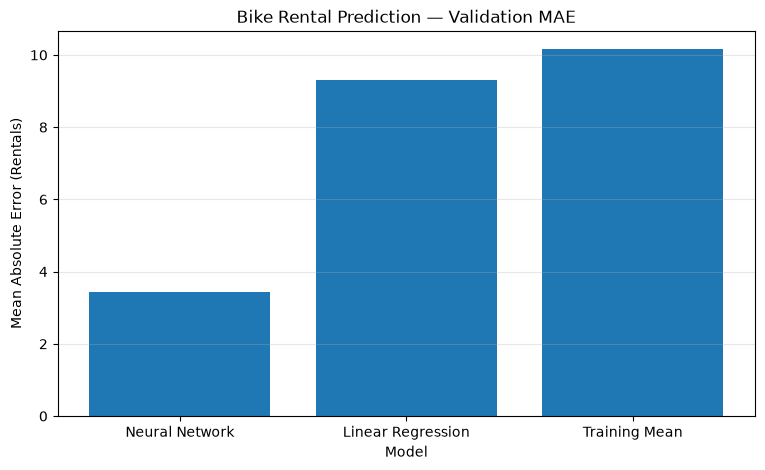

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Model"],
    comparison["Validation MAE"]
)

plt.xlabel("Model")
plt.ylabel("Mean Absolute Error (Rentals)")
plt.title("Bike Rental Prediction — Validation MAE")

plt.grid(axis="y", alpha=0.3)
plt.show()

In [52]:
assert len(mean_predictions) == len(y_val)
assert len(linear_predictions) == len(y_val)
assert len(val_dataset) == len(y_val)

assert X_train_prepared.shape[0] == len(y_train)
assert X_val_prepared.shape[0] == len(y_val)

print("Both baselines use the same training and validation rows!")

Both baselines use the same training and validation rows!


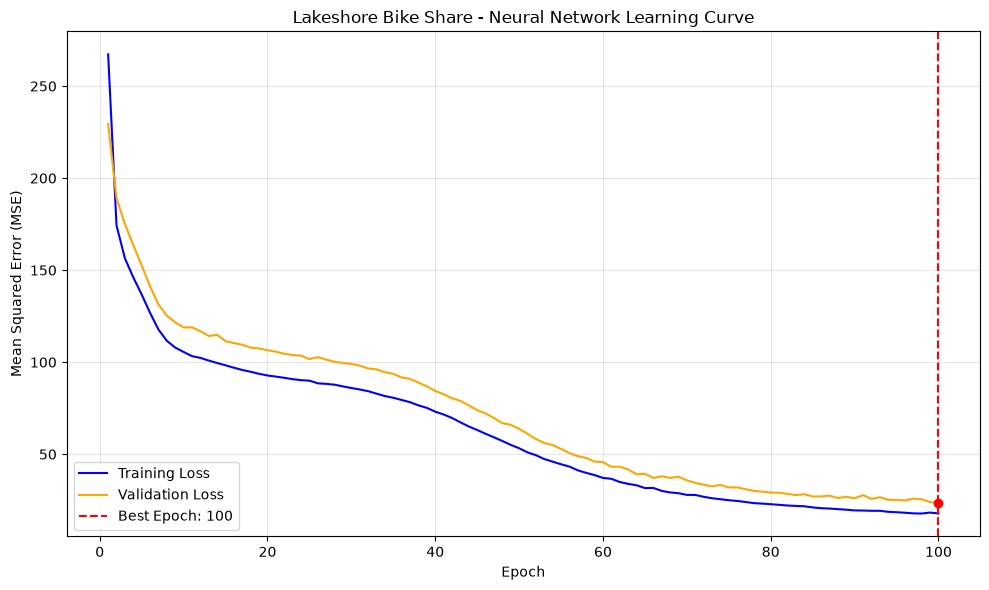

Best epoch: 100
Best validation loss: 23.7446
Saved to: reports\learning_curve.png


In [53]:
import matplotlib.pyplot as plt
from pathlib import Path

# Identify the epoch with the lowest validation loss
best_idx = history["val_loss"].idxmin()
best_epoch = int(history.loc[best_idx, "epoch"])
best_val_loss = history.loc[best_idx, "val_loss"]

# Create learning curve
plt.figure(figsize=(10, 6))

plt.plot(
    history["epoch"],
    history["train_loss"],
    label="Training Loss",
    color="blue"
)

plt.plot(
    history["epoch"],
    history["val_loss"],
    label="Validation Loss",
    color="orange"
)

# Mark the best epoch
plt.axvline(
    x=best_epoch,
    color="red",
    linestyle="--",
    label=f"Best Epoch: {best_epoch}"
)

plt.scatter(
    best_epoch,
    best_val_loss,
    color="red",
    zorder=5
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Lakeshore Bike Share - Neural Network Learning Curve")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Create reports directory if needed
output_path = Path("reports")
output_path.mkdir(exist_ok=True)

# Save PNG
plt.savefig(
    output_path / "learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Saved to:", output_path / "learning_curve.png")

In [54]:
from pathlib import Path

plot_file = Path("reports/learning_curve.png")

assert plot_file.is_file(), "Learning curve PNG was not saved."
assert plot_file.stat().st_size > 0, "PNG file is empty."

print("Learning curve PNG verified!")
print("File:", plot_file.resolve())

Learning curve PNG verified!
File: C:\Users\juans\OneDrive\Desktop\lab7LbsArtLobrin\reports\learning_curve.png


In [57]:
class BikeRentalNNExperiment(nn.Module):
    def __init__(self, input_size, hidden1=64, hidden2=32):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, hidden1),
            nn.ReLU(),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Linear(hidden2, 1)
        )

    def forward(self, x):
        return self.network(x)

In [58]:
# Experimental configurations
experiments = [
    {
        "name": "Main",
        "hidden1": 64,
        "hidden2": 32,
        "lr": 0.001
    },
    {
        "name": "Lower Learning Rate",
        "hidden1": 64,
        "hidden2": 32,
        "lr": 0.0005
    },
    {
        "name": "Larger Hidden Layer",
        "hidden1": 128,
        "hidden2": 32,
        "lr": 0.001
    }
]

results = []
experiment_histories = {}
experiment_models = {}

for config in experiments:

    print(f"\nRunning: {config['name']}")

    # Same seed for each experiment
    torch.manual_seed(42)

    experiment_model = BikeRentalNNExperiment(
        input_size=X_train_prepared.shape[1],
        hidden1=config["hidden1"],
        hidden2=config["hidden2"]
    )

    experiment_optimizer = torch.optim.Adam(
        experiment_model.parameters(),
        lr=config["lr"]
    )

    experiment_history = train_model(
        experiment_model,
        train_loader,
        val_loader,
        loss_fn,
        experiment_optimizer,
        epochs=100
    )

    # train_model restores the best weights
    best_row = experiment_history.loc[
        experiment_history["val_loss"].idxmin()
    ]

    results.append({
        "Run": config["name"],
        "Hidden Layers": f"{config['hidden1']}, {config['hidden2']}",
        "Learning Rate": config["lr"],
        "Best Epoch": int(best_row["epoch"]),
        "Validation Loss": best_row["val_loss"],
        "Validation MAE": best_row["val_mae"]
    })

    experiment_histories[config["name"]] = experiment_history
    experiment_models[config["name"]] = experiment_model


Running: Main
Epoch 001/100 | Train Loss: 267.2774 | Val Loss: 229.4696 | Val MAE: 9.2289
Epoch 002/100 | Train Loss: 174.3179 | Val Loss: 189.1155 | Val MAE: 9.4422
Epoch 003/100 | Train Loss: 156.4382 | Val Loss: 175.1133 | Val MAE: 9.0501
Epoch 004/100 | Train Loss: 146.0816 | Val Loss: 163.5826 | Val MAE: 8.5963
Epoch 005/100 | Train Loss: 136.7707 | Val Loss: 152.5628 | Val MAE: 8.0461
Epoch 006/100 | Train Loss: 126.8061 | Val Loss: 141.2778 | Val MAE: 7.5531
Epoch 007/100 | Train Loss: 117.7435 | Val Loss: 131.3453 | Val MAE: 7.6388
Epoch 008/100 | Train Loss: 111.6035 | Val Loss: 125.2623 | Val MAE: 7.4605
Epoch 009/100 | Train Loss: 107.9329 | Val Loss: 121.6431 | Val MAE: 7.3062
Epoch 010/100 | Train Loss: 105.5532 | Val Loss: 118.8624 | Val MAE: 7.2918
Epoch 011/100 | Train Loss: 103.2910 | Val Loss: 118.9306 | Val MAE: 7.5047
Epoch 012/100 | Train Loss: 102.3267 | Val Loss: 116.8229 | Val MAE: 7.0657
Epoch 013/100 | Train Loss: 100.8788 | Val Loss: 114.2583 | Val MAE: 7.03

In [59]:
print(experiment_comparison.round(4).to_markdown(index=False))

NameError: name 'experiment_comparison' is not defined

In [60]:
import pandas as pd

experiment_comparison = pd.DataFrame(results)

print(experiment_comparison.round(4))

                   Run Hidden Layers  Learning Rate  Best Epoch  \
0                 Main        64, 32         0.0010         100   
1  Lower Learning Rate        64, 32         0.0005         100   
2  Larger Hidden Layer       128, 32         0.0010          98   

   Validation Loss  Validation MAE  
0          23.7446          3.4244  
1          72.5713          5.4695  
2          15.7356          2.6661  


In [61]:
print(experiment_comparison.round(4).to_markdown(index=False))

| Run                 | Hidden Layers   |   Learning Rate |   Best Epoch |   Validation Loss |   Validation MAE |
|:--------------------|:----------------|----------------:|-------------:|------------------:|-----------------:|
| Main                | 64, 32          |          0.001  |          100 |           23.7446 |           3.4244 |
| Lower Learning Rate | 64, 32          |          0.0005 |          100 |           72.5713 |           5.4695 |
| Larger Hidden Layer | 128, 32         |          0.001  |           98 |           15.7356 |           2.6661 |
